<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Procesamiento de Lenguaje Natural**
## **Desafio, Traductor**

**Este desafío puede realizarse de manera individual o en pareja. En caso de realizarlo en pareja, solo uno de los integrantes deberá subir el desafío.**

*Nombre: Manuel Dieguez (a2518)*

### **Consigna**

* Replicar el modelo traductor desarrollado en clase (https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/blob/set_2026/Clase%206/C%C3%B3digo/Traductor.ipynb) y extender su entrenamiento utilizando un conjunto de datos más amplio y secuencias de mayor longitud.
* Modificar valores de hiperparámetros (por ejemplo, el número de unidades en las capas LSTM) y analizar su impacto en el desempeño del traductor.
* Analizar el impacto del número de neuronas en las capas recurrentes, comparando el desempeño de distintas configuraciones del modelo.
* Generar y presentar al menos cinco ejemplos de traducciones producidas por el modelo entrenado.
* Interpretar a detalle los resultados obtenidos, considerando métricas de evaluación, calidad de las traducciones y posibles limitaciones del enfoque utilizado.

### **Actividades opcionales**

* Incorporar embeddings preentrenados para ambos idiomas y evaluar su efecto sobre el rendimiento del modelo.
* Experimentar con diferentes estrategias de generación de secuencias, como muestreo aleatorio (sampling) o búsqueda por haz (beam search).
* Implementar y entrenar una versión equivalente del modelo utilizando PyTorch, comparando los resultados con la implementación original.

### **Plan de trabajo de este notebook**

1. Dataset ampliado (~35.000 oraciones) con secuencias más largas que en el ejercicio de clase.
2. Barrido de hiperparámetros: 3 configuraciones de unidades LSTM (128 / 256 / 512), comparando curvas de entrenamiento y validación.
3. Comparación **con embeddings preentrenados** (inglés: GloVe, español: FastText) **vs. sin embeddings preentrenados** (ambos entrenados desde cero), usando la mejor configuración de unidades hallada en el paso 2.
4. Generación de traducciones de ejemplo (≥5) con el mejor modelo.
5. Interpretación detallada de resultados y limitaciones.

## 1. Imports

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.layers import Input, LSTM, Dense, Embedding, Dropout
from tensorflow.keras.models import Model
import pickle
import os
import gzip
import urllib.request
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

np.random.seed(40)
tf.random.set_seed(40)

## 2. Dataset

Usamos el mismo corpus Español-Inglés del ejercicio de clase, pero ampliamos considerablemente la cantidad de oraciones y la longitud máxima de las secuencias para analizar el impacto en el desempeño del traductor.

In [2]:
if not os.path.exists('spa-eng'):
    os.system("curl -L -o spa-eng.zip http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip")
    os.system("unzip -q spa-eng.zip")

with open("./spa-eng/spa.txt", encoding="utf-8") as f:
    lines = f.read().split("\n")[:-1]

print(f"Oraciones totales disponibles en el corpus: {len(lines)}")

Oraciones totales disponibles en el corpus: 118964


In [3]:
# Ampliamos respecto del ejercicio de clase (10.000 -> 35.000 oraciones)
MAX_NUM_SENTENCES = 35000

np.random.shuffle(lines)

In [4]:
input_sentences, output_sentences, output_sentences_inputs = [], [], []

for i, line in enumerate(lines):
    if i >= MAX_NUM_SENTENCES:
        break
    if '\t' not in line:
        continue
    input_sentence, output = line.rstrip().split('\t')[:2]
    output_sentences.append(output + ' <eos>')
    output_sentences_inputs.append('<sos> ' + output)
    input_sentences.append(input_sentence)

print(f"Oraciones cargadas: {len(input_sentences)}")

Oraciones cargadas: 35000


In [5]:
print(input_sentences[0])
print(output_sentences[0])
print(output_sentences_inputs[0])

Somebody stole my car.
Alguien robó mi auto. <eos>
<sos> Alguien robó mi auto.


### Tokenización

Ampliamos también el vocabulario máximo (8.000 -> 16.000) dado que el dataset es más grande.

In [6]:
MAX_VOCAB_SIZE = 16000

input_tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE)
input_tokenizer.fit_on_texts(input_sentences)
input_integer_seq = input_tokenizer.texts_to_sequences(input_sentences)
word2idx_inputs = input_tokenizer.word_index

output_tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    filters='!"#$%&()*+,-./:;=¿?@[\\]^_`{|}~\t\n'
)

output_tokenizer.fit_on_texts(["<sos>", "<eos>"] + output_sentences)
output_integer_seq = output_tokenizer.texts_to_sequences(output_sentences)
output_input_integer_seq = output_tokenizer.texts_to_sequences(output_sentences_inputs)
word2idx_outputs = output_tokenizer.word_index

num_words_output = min(len(word2idx_outputs) + 1, MAX_VOCAB_SIZE)

# Longitudes ampliadas respecto del ejercicio de clase (20/22 -> 30/34)
lengths_in = [len(s) for s in input_integer_seq]
lengths_out = [len(s) for s in output_integer_seq]
print(f"Percentil 95 longitud entrada: {np.percentile(lengths_in, 95):.1f}")
print(f"Percentil 95 longitud salida:  {np.percentile(lengths_out, 95):.1f}")

max_input_len = 30
max_out_len   = 34

print(f"Vocabulario EN: {len(word2idx_inputs)} | ES: {len(word2idx_outputs)}")
print(f"max_input_len={max_input_len}  max_out_len={max_out_len}")

Percentil 95 longitud entrada: 11.0
Percentil 95 longitud salida:  12.0
Vocabulario EN: 8665 | ES: 15123
max_input_len=30  max_out_len=34


In [7]:
encoder_input_sequences  = pad_sequences(input_integer_seq,        maxlen=max_input_len)
decoder_input_sequences  = pad_sequences(output_input_integer_seq, maxlen=max_out_len, padding='post')
decoder_output_sequences = pad_sequences(output_integer_seq,       maxlen=max_out_len, padding='post')

print(encoder_input_sequences[0])
print(decoder_input_sequences[0])
print(decoder_output_sequences[0])

[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0  894 1081
   18   95]
[7690  157 1167   22  199    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0]
[ 157 1167   22  199    1    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0]


### Pipeline `tf.data.Dataset`

In [8]:
def make_dataset(enc_seqs, dec_in_seqs, dec_out_seqs, batch_size, num_classes):

    n = len(enc_seqs)

    def generator():
        for i in range(n):
            yield (
                enc_seqs[i].astype(np.int32),
                dec_in_seqs[i].astype(np.int32),
                dec_out_seqs[i].astype(np.int32),
            )

    def encode_one_hot(enc, dec_in, dec_out):
        y = tf.one_hot(dec_out, depth=num_classes)
        return (enc, dec_in), y

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(max_input_len,), dtype=tf.int32),
            tf.TensorSpec(shape=(max_out_len,),   dtype=tf.int32),
            tf.TensorSpec(shape=(max_out_len,),   dtype=tf.int32),
        )
    )
    ds = ds.map(encode_one_hot, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

In [9]:
BATCH_SIZE = 64
val_split  = 0.15
split_idx  = int(len(encoder_input_sequences) * (1 - val_split))

train_ds = make_dataset(
    encoder_input_sequences[:split_idx],
    decoder_input_sequences[:split_idx],
    decoder_output_sequences[:split_idx],
    BATCH_SIZE, num_words_output
)
val_ds = make_dataset(
    encoder_input_sequences[split_idx:],
    decoder_input_sequences[split_idx:],
    decoder_output_sequences[split_idx:],
    BATCH_SIZE, num_words_output
)

print(f"Oraciones de entrenamiento: {split_idx} | validación: {len(encoder_input_sequences) - split_idx}")

Oraciones de entrenamiento: 29750 | validación: 5250


## 3. Embeddings preentrenados

Para comparar el entrenamiento **con** y **sin** embeddings preentrenados (actividad opcional), armamos matrices de embeddings preentrenados para ambos idiomas:

* **Inglés (encoder)**: GloVe 50d (mismo recurso que en el ejercicio de clase).
* **Español (decoder)**: FastText 300d (`cc.es.300.vec`), descargando solo las primeras líneas del archivo comprimido (ordenado por frecuencia) hasta cubrir el vocabulario que necesitamos, sin descargar el archivo completo (~1.3 GB).

### 3.1 Embeddings en inglés (GloVe)

In [10]:
def _is_valid_pickle(path):
    try:
        with open(path, 'rb') as f:
            head = f.read(20)
        return b'<html' not in head.lower() and b'<!doctype' not in head.lower()
    except Exception:
        return False

_PKL_PATH = 'gloveembedding.pkl'
_FILE_ID  = '1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94'

if not os.path.exists(_PKL_PATH) or not _is_valid_pickle(_PKL_PATH):
    print("Descargando gloveembedding.pkl desde Google Drive...")
    if os.path.exists(_PKL_PATH):
        os.remove(_PKL_PATH)
    try:
        import gdown
        gdown.download(id=_FILE_ID, output=_PKL_PATH, quiet=False)
    except Exception:
        os.system(f"curl -L -o {_PKL_PATH} "
                  f"'https://drive.google.com/u/0/uc?id={_FILE_ID}&export=download&confirm=t'")
    if not _is_valid_pickle(_PKL_PATH):
        raise ValueError("El archivo descargado no es un pickle válido.")
    print("Descarga completada.")
else:
    print("gloveembedding.pkl ya disponible.")

Descargando gloveembedding.pkl desde Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94
From (redirected): https://drive.google.com/uc?id=1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94&confirm=t&uuid=abab6f59-c13f-42df-8fd7-5d20e288477e
To: /content/gloveembedding.pkl
100%|██████████| 525M/525M [00:08<00:00, 58.5MB/s]

Descarga completada.


In [11]:
def load_glove_embeddings(pkl_path):
    """Carga el pickle de GloVe y devuelve (embeddings, word2idx)."""
    max_bytes = 2**28 - 1
    raw = bytearray()
    sz  = os.path.getsize(pkl_path)
    with open(pkl_path, 'rb') as f:
        for _ in range(0, sz, max_bytes):
            raw += f.read(max_bytes)
    embeddings = pickle.loads(raw)
    idx_array  = np.arange(embeddings.shape[0])
    word2idx   = dict(zip(embeddings['word'], idx_array))
    return embeddings, word2idx


def get_word_embedding(word, embeddings, word2idx, n_features=50):
    i = word2idx.get(word, -1)
    return embeddings[i]['embedding'] if i != -1 else np.zeros(n_features)


def build_embedding_matrix_glove(word2idx_vocab, embeddings, word2idx_glove,
                                  nb_words, embed_dim=50):
    matrix = np.zeros((nb_words, embed_dim))
    for word, i in word2idx_vocab.items():
        if i < nb_words:
            vec = get_word_embedding(word, embeddings, word2idx_glove, embed_dim)
            if vec is not None and len(vec) > 0:
                matrix[i] = vec
    return matrix

In [12]:
EMBED_DIM_EN = 50
nb_words_en  = min(MAX_VOCAB_SIZE, len(word2idx_inputs) + 1)

glove_embeddings, glove_word2idx = load_glove_embeddings(_PKL_PATH)
embedding_matrix_en = build_embedding_matrix_glove(
    word2idx_inputs, glove_embeddings, glove_word2idx, nb_words_en, EMBED_DIM_EN
)
print(f"Embeddings EN nulos: {np.sum(np.sum(embedding_matrix_en**2, axis=1) == 0)} / {nb_words_en}")

Embeddings EN nulos: 445 / 8666


### 3.2 Embeddings en español (FastText)

Descargamos el archivo comprimido de FastText en modo *streaming*, lo descomprimimos al vuelo y nos quedamos únicamente con los vectores de las palabras que están en nuestro vocabulario español, cortando la descarga apenas las cubrimos (o tras un máximo de líneas de seguridad). Esto evita bajar el archivo completo (~1.3 GB).

In [13]:
FASTTEXT_ES_URL = "https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.es.300.vec.gz"
EMBED_DIM_ES = 300
MAX_LINES_SAFETY = 400000  # tope de líneas a inspeccionar aunque no se complete el vocabulario


def download_fasttext_subset(url, vocab, embed_dim, max_lines=MAX_LINES_SAFETY):
    """Descarga en streaming un .vec.gz de FastText y devuelve {palabra: vector}
    solo para las palabras presentes en `vocab`, sin bajar el archivo completo."""
    found = {}
    pending = set(vocab)
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as resp:
        with gzip.GzipFile(fileobj=resp) as gz:
            for i, raw_line in enumerate(gz):
                if i == 0:
                    continue  # primera línea: cabecera con (n_vectores, dim)
                if not pending or i >= max_lines:
                    break
                line = raw_line.decode('utf-8', errors='ignore')
                word, _, rest = line.partition(' ')
                if word in pending:
                    vec = np.fromstring(rest, sep=' ', dtype=np.float32)
                    if len(vec) == embed_dim:
                        found[word] = vec
                        pending.discard(word)
    return found


_FASTTEXT_CACHE = 'fasttext_es_subset.pkl'

if os.path.exists(_FASTTEXT_CACHE):
    with open(_FASTTEXT_CACHE, 'rb') as f:
        fasttext_es_vectors = pickle.load(f)
    print(f"Vectores FastText ES cargados desde cache: {len(fasttext_es_vectors)}")
else:
    print("Descargando subconjunto de embeddings FastText (español) en streaming...")
    vocab_es = set(word2idx_outputs.keys())
    fasttext_es_vectors = download_fasttext_subset(FASTTEXT_ES_URL, vocab_es, EMBED_DIM_ES)
    with open(_FASTTEXT_CACHE, 'wb') as f:
        pickle.dump(fasttext_es_vectors, f)
    print(f"Vectores encontrados: {len(fasttext_es_vectors)} / {len(vocab_es)}")

Descargando subconjunto de embeddings FastText (español) en streaming...
Vectores encontrados: 14107 / 15123


In [14]:
def build_embedding_matrix_fasttext(word2idx_vocab, vectors_dict, nb_words, embed_dim):
    matrix = np.zeros((nb_words, embed_dim))
    hits = 0
    for word, i in word2idx_vocab.items():
        if i < nb_words and word in vectors_dict:
            matrix[i] = vectors_dict[word]
            hits += 1
    return matrix, hits


nb_words_es = num_words_output
embedding_matrix_es, hits_es = build_embedding_matrix_fasttext(
    word2idx_outputs, fasttext_es_vectors, nb_words_es, EMBED_DIM_ES
)
print(f"Embeddings ES encontrados: {hits_es} / {nb_words_es}")

Embeddings ES encontrados: 14107 / 15124


## 4. Modelo Seq2Seq parametrizable

Convertimos la construcción del encoder/decoder del ejercicio de clase en funciones parametrizadas por:

* `n_units`: número de unidades en las capas LSTM (para el barrido de hiperparámetros).
* `use_pretrained_embeddings`: si `True`, inicializa los embeddings con las matrices preentrenadas (GloVe/FastText) y los congela (`trainable=False`); si `False`, los embeddings se entrenan desde cero junto con el resto del modelo.

In [15]:
def build_encoder(nb_words, embed_dim, max_input_len, n_units,
                   embedding_matrix=None, trainable=True):

    enc_inputs = Input(shape=(max_input_len,), name='encoder_inputs')

    emb_kwargs = dict(input_dim=nb_words, output_dim=embed_dim, name='encoder_embedding')
    if embedding_matrix is not None:
        emb_kwargs['weights'] = [embedding_matrix]
    emb_kwargs['trainable'] = trainable

    enc_emb_layer = Embedding(**emb_kwargs)
    enc_emb = Dropout(0.3, name='encoder_dropout')(enc_emb_layer(enc_inputs))

    enc_lstm_layer = LSTM(n_units, return_state=True, name='encoder_lstm')
    _, state_h, state_c = enc_lstm_layer(enc_emb)

    return enc_inputs, [state_h, state_c], enc_emb_layer, enc_lstm_layer


def build_decoder(num_words_output, embed_dim, max_out_len, n_units, encoder_states,
                   embedding_matrix=None, trainable=True):

    dec_inputs = Input(shape=(max_out_len,), name='decoder_inputs')

    emb_kwargs = dict(input_dim=num_words_output, output_dim=embed_dim, name='decoder_embedding')
    if embedding_matrix is not None:
        emb_kwargs['weights'] = [embedding_matrix]
    emb_kwargs['trainable'] = trainable

    dec_emb_layer = Embedding(**emb_kwargs)
    dec_emb = Dropout(0.3, name='decoder_dropout')(dec_emb_layer(dec_inputs))

    dec_lstm_layer = LSTM(n_units, return_sequences=True, return_state=True, name='decoder_lstm')
    dec_out, _, _  = dec_lstm_layer(dec_emb, initial_state=encoder_states)

    dec_dense_layer = Dense(num_words_output, activation='softmax', name='decoder_dense')
    dec_out = dec_dense_layer(dec_out)

    return dec_inputs, dec_out, dec_emb_layer, dec_lstm_layer, dec_dense_layer


def build_seq2seq_model(n_units, use_pretrained_embeddings):
    """Construye el modelo de entrenamiento y devuelve también las capas
    necesarias para armar luego los modelos de inferencia."""

    enc_embed_dim = EMBED_DIM_EN if use_pretrained_embeddings else 100
    dec_embed_dim = EMBED_DIM_ES if use_pretrained_embeddings else 100

    enc_matrix = embedding_matrix_en if use_pretrained_embeddings else None
    dec_matrix = embedding_matrix_es if use_pretrained_embeddings else None

    # Si hay embeddings preentrenados los congelamos; si no, se entrenan desde cero.
    enc_trainable = not use_pretrained_embeddings
    dec_trainable = not use_pretrained_embeddings

    enc_inputs, enc_states, enc_emb_layer, enc_lstm_layer = build_encoder(
        nb_words_en, enc_embed_dim, max_input_len, n_units,
        embedding_matrix=enc_matrix, trainable=enc_trainable
    )
    dec_inputs, dec_outputs, dec_emb_layer, dec_lstm_layer, dec_dense_layer = build_decoder(
        num_words_output, dec_embed_dim, max_out_len, n_units, enc_states,
        embedding_matrix=dec_matrix, trainable=dec_trainable
    )

    model = Model([enc_inputs, dec_inputs], dec_outputs)

    layers = dict(
        enc_inputs=enc_inputs, enc_emb_layer=enc_emb_layer, enc_lstm_layer=enc_lstm_layer,
        dec_emb_layer=dec_emb_layer, dec_lstm_layer=dec_lstm_layer, dec_dense_layer=dec_dense_layer,
        n_units=n_units
    )
    return model, layers


def compile_and_train(model, epochs=15, lr=5e-4):
    model.compile(
        loss='categorical_crossentropy',
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        metrics=['accuracy']
    )
    lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=0)
    early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1)

    hist = model.fit(
        train_ds, validation_data=val_ds, epochs=epochs,
        callbacks=[lr_scheduler, early_stop], verbose=1
    )
    return hist

## 5. Barrido de hiperparámetros: unidades LSTM

Entrenamos tres configuraciones (`n_units` = 128, 256, 512), todas con embeddings preentrenados, para analizar el impacto de la capacidad de las capas recurrentes en el desempeño del traductor.

In [16]:
N_UNITS_GRID = [128, 256, 512]
EPOCHS_GRID = 15

histories_units = {}
models_units = {}

for n_units in N_UNITS_GRID:
    print(f"\n=== Entrenando con n_units={n_units} ===")
    model, layers = build_seq2seq_model(n_units=n_units, use_pretrained_embeddings=True)
    hist = compile_and_train(model, epochs=EPOCHS_GRID)
    histories_units[n_units] = hist.history
    models_units[n_units] = (model, layers)


=== Entrenando con n_units=128 ===
Epoch 1/15
    465/Unknown 55s 104ms/step - accuracy: 0.7735 - loss: 3.9317

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


465/465 ━━━━━━━━━━━━━━━━━━━━ 64s 123ms/step - accuracy: 0.7900 - loss: 2.1928 - val_accuracy: 0.8015 - val_loss: 1.3333 - learning_rate: 5.0000e-04
Epoch 2/15
465/465 ━━━━━━━━━━━━━━━━━━━━ 58s 126ms/step - accuracy: 0.8193 - loss: 1.2611 - val_accuracy: 0.8274 - val_loss: 1.2334 - learning_rate: 5.0000e-04
Epoch 3/15
465/465 ━━━━━━━━━━━━━━━━━━━━ 83s 178ms/step - accuracy: 0.8320 - loss: 1.1772 - val_accuracy: 0.8337 - val_loss: 1.1689 - learning_rate: 5.0000e-04
Epoch 4/15
465/465 ━━━━━━━━━━━━━━━━━━━━ 60s 129ms/step - accuracy: 0.8365 - loss: 1.1174 - val_accuracy: 0.8377 - val_loss: 1.1200 - learning_rate: 5.0000e-04
Epoch 5/15
465/465 ━━━━━━━━━━━━━━━━━━━━ 82s 176ms/step - accuracy: 0.8404 - loss: 1.0687 - val_accuracy: 0.8414 - val_loss: 1.0793 - learning_rate: 5.0000e-04
Epoch 6/15
465/465 ━━━━━━━━━━━━━━━━━━━━ 60s 129ms/step - accuracy: 0.8432 - loss: 1.0275 - val_accuracy: 0.8438 - val_loss: 1.0456 - learning_rate: 5.0000e-04
Epoch 7/15
465/465 ━━━━━━━━━━━━━━━━━━━━ 83s 178ms/step - 

In [17]:
rows = []
for n_units, h in histories_units.items():
    best_epoch = int(np.argmin(h['val_loss']))
    rows.append({
        'n_units': n_units,
        'epochs_entrenadas': len(h['val_loss']),
        'train_loss_final': h['loss'][best_epoch],
        'val_loss_final': h['val_loss'][best_epoch],
        'train_acc_final': h['accuracy'][best_epoch],
        'val_acc_final': h['val_accuracy'][best_epoch],
    })

df_units = pd.DataFrame(rows).sort_values('val_loss_final')
df_units

,n_units,epochs_entrenadas,train_loss_final,val_loss_final,train_acc_final,val_acc_final
2,512,15,0.524682,0.742921,0.885782,0.877289
1,256,15,0.660155,0.791577,0.869653,0.869255
0,128,15,0.807119,0.886871,0.857307,0.858179


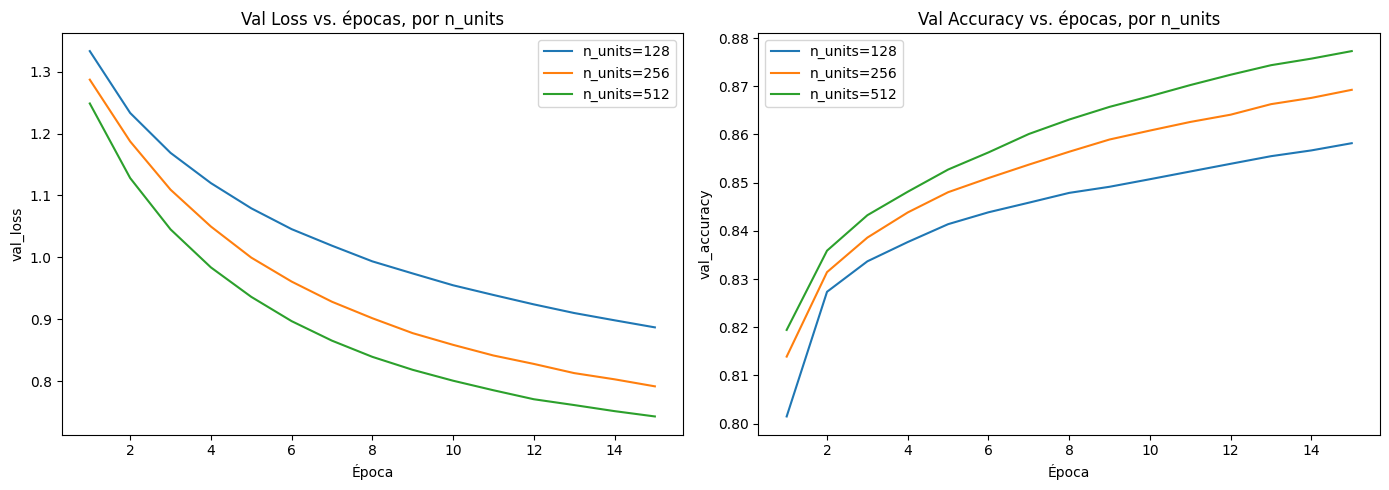

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for n_units, h in histories_units.items():
    epochs_range = range(1, len(h['loss']) + 1)
    axes[0].plot(epochs_range, h['val_loss'], label=f'n_units={n_units}')
    axes[1].plot(epochs_range, h['val_accuracy'], label=f'n_units={n_units}')

axes[0].set_title('Val Loss vs. épocas, por n_units')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('val_loss'); axes[0].legend()

axes[1].set_title('Val Accuracy vs. épocas, por n_units')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('val_accuracy'); axes[1].legend()

plt.tight_layout()
plt.show()

In [19]:
BEST_N_UNITS = int(df_units.iloc[0]['n_units'])
print(f"Mejor configuración de unidades LSTM según val_loss: n_units={BEST_N_UNITS}")

Mejor configuración de unidades LSTM según val_loss: n_units=512


## 6. Comparación con y sin embeddings preentrenados

Usando la mejor configuración de unidades LSTM hallada en el paso anterior, entrenamos dos modelos:

* **Con embeddings preentrenados**: encoder inicializado con GloVe (inglés) y decoder con FastText (español), ambos congelados.
* **Sin embeddings preentrenados**: encoder y decoder con embeddings inicializados aleatoriamente y entrenados desde cero junto con el resto de la red.

Esto nos permite aislar el efecto de los embeddings preentrenados, manteniendo fija la arquitectura y el resto de los hiperparámetros.

In [20]:
EPOCHS_ABLATION = 20

print("=== Entrenando CON embeddings preentrenados ===")
model_with_emb, layers_with_emb = build_seq2seq_model(n_units=BEST_N_UNITS, use_pretrained_embeddings=True)
hist_with_emb = compile_and_train(model_with_emb, epochs=EPOCHS_ABLATION)

=== Entrenando CON embeddings preentrenados ===
Epoch 1/20
    465/Unknown 78s 164ms/step - accuracy: 0.7864 - loss: 2.3760

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


465/465 ━━━━━━━━━━━━━━━━━━━━ 88s 185ms/step - accuracy: 0.8062 - loss: 1.5611 - val_accuracy: 0.8213 - val_loss: 1.2421 - learning_rate: 5.0000e-04
Epoch 2/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 142s 305ms/step - accuracy: 0.8306 - loss: 1.1629 - val_accuracy: 0.8361 - val_loss: 1.1290 - learning_rate: 5.0000e-04
Epoch 3/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 85s 183ms/step - accuracy: 0.8401 - loss: 1.0541 - val_accuracy: 0.8429 - val_loss: 1.0430 - learning_rate: 5.0000e-04
Epoch 4/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 143s 307ms/step - accuracy: 0.8462 - loss: 0.9693 - val_accuracy: 0.8489 - val_loss: 0.9769 - learning_rate: 5.0000e-04
Epoch 5/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 85s 184ms/step - accuracy: 0.8514 - loss: 0.8989 - val_accuracy: 0.8535 - val_loss: 0.9283 - learning_rate: 5.0000e-04
Epoch 6/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 143s 307ms/step - accuracy: 0.8556 - loss: 0.8390 - val_accuracy: 0.8579 - val_loss: 0.8850 - learning_rate: 5.0000e-04
Epoch 7/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 145s 185ms/ste

In [21]:
print("=== Entrenando SIN embeddings preentrenados ===")
model_without_emb, layers_without_emb = build_seq2seq_model(n_units=BEST_N_UNITS, use_pretrained_embeddings=False)
hist_without_emb = compile_and_train(model_without_emb, epochs=EPOCHS_ABLATION)

=== Entrenando SIN embeddings preentrenados ===
Epoch 1/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 88s 185ms/step - accuracy: 0.8164 - loss: 1.5201 - val_accuracy: 0.8261 - val_loss: 1.2351 - learning_rate: 5.0000e-04
Epoch 2/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 141s 183ms/step - accuracy: 0.8318 - loss: 1.1720 - val_accuracy: 0.8321 - val_loss: 1.1678 - learning_rate: 5.0000e-04
Epoch 3/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 85s 183ms/step - accuracy: 0.8368 - loss: 1.1005 - val_accuracy: 0.8366 - val_loss: 1.1128 - learning_rate: 5.0000e-04
Epoch 4/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 142s 183ms/step - accuracy: 0.8418 - loss: 1.0340 - val_accuracy: 0.8425 - val_loss: 1.0587 - learning_rate: 5.0000e-04
Epoch 5/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 86s 184ms/step - accuracy: 0.8466 - loss: 0.9674 - val_accuracy: 0.8465 - val_loss: 1.0113 - learning_rate: 5.0000e-04
Epoch 6/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 86s 184ms/step - accuracy: 0.8512 - loss: 0.9078 - val_accuracy: 0.8500 - val_loss: 0.9739 - learning_rate: 5.0000e

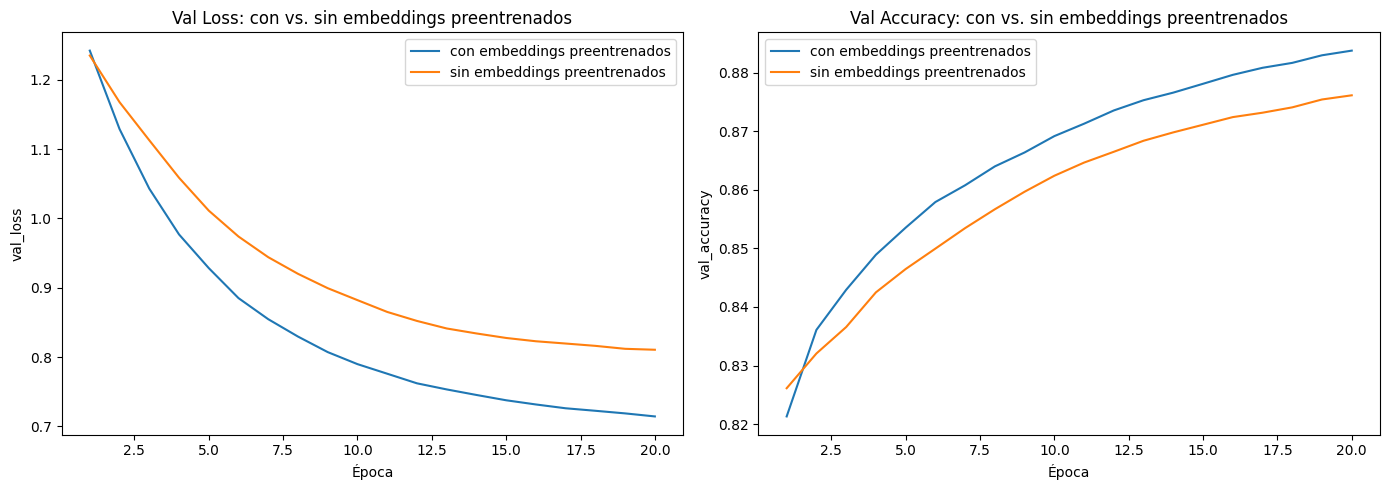

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, h in [('con embeddings preentrenados', hist_with_emb.history),
                  ('sin embeddings preentrenados', hist_without_emb.history)]:
    epochs_range = range(1, len(h['loss']) + 1)
    axes[0].plot(epochs_range, h['val_loss'], label=label)
    axes[1].plot(epochs_range, h['val_accuracy'], label=label)

axes[0].set_title('Val Loss: con vs. sin embeddings preentrenados')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('val_loss'); axes[0].legend()

axes[1].set_title('Val Accuracy: con vs. sin embeddings preentrenados')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('val_accuracy'); axes[1].legend()

plt.tight_layout()
plt.show()

In [23]:
print(f"CON embeddings  -> val_loss: {min(hist_with_emb.history['val_loss']):.4f} | "
      f"val_accuracy: {max(hist_with_emb.history['val_accuracy']):.4f}")
print(f"SIN embeddings  -> val_loss: {min(hist_without_emb.history['val_loss']):.4f} | "
      f"val_accuracy: {max(hist_without_emb.history['val_accuracy']):.4f}")

CON embeddings  -> val_loss: 0.7143 | val_accuracy: 0.8837
SIN embeddings  -> val_loss: 0.8105 | val_accuracy: 0.8761


## 7. Inferencia y generación de traducciones

Armamos los modelos de inferencia (encoder/decoder paso a paso) para el modelo final elegido (el de mejor desempeño entre las comparaciones anteriores) y generamos traducciones de ejemplo.

In [24]:
def build_encoder_inference(enc_inputs, enc_emb_layer, enc_lstm_layer):
    enc_emb = enc_emb_layer(enc_inputs)
    _, state_h, state_c = enc_lstm_layer(enc_emb)
    return Model(enc_inputs, [state_h, state_c])


def build_decoder_inference(dec_emb_layer, dec_lstm_layer, dec_dense_layer, n_units):
    dec_input_single = Input(shape=(1,), name='dec_input_single')
    dec_state_h_in   = Input(shape=(n_units,), name='dec_state_h')
    dec_state_c_in   = Input(shape=(n_units,), name='dec_state_c')

    dec_emb_single = dec_emb_layer(dec_input_single)
    dec_out, h_out, c_out = dec_lstm_layer(
        dec_emb_single, initial_state=[dec_state_h_in, dec_state_c_in]
    )
    dec_out = dec_dense_layer(dec_out)

    return Model([dec_input_single, dec_state_h_in, dec_state_c_in], [dec_out, h_out, c_out])


idx2word_input  = {v: k for k, v in word2idx_inputs.items()}
idx2word_target = {v: k for k, v in word2idx_outputs.items()}


def translate_sentence(input_seq, encoder_model, decoder_model, n_units):
    h, c = encoder_model.predict(input_seq, verbose=0)
    target_seq = np.zeros((1, 1))
    target_seq[0, 0] = word2idx_outputs['<sos>']
    eos = word2idx_outputs['<eos>']

    output_sentence = []
    for _ in range(max_out_len):
        output_tokens, h, c = decoder_model.predict([target_seq, h, c], verbose=0)
        idx = np.argmax(output_tokens[0, 0, :])
        if idx == eos:
            break
        if idx > 0:
            output_sentence.append(idx2word_target[idx])
        target_seq[0, 0] = idx

    return ' '.join(output_sentence)


def translate(text, encoder_model, decoder_model, n_units):
    seq = input_tokenizer.texts_to_sequences([text])
    seq = pad_sequences(seq, maxlen=max_input_len)
    return translate_sentence(seq, encoder_model, decoder_model, n_units)

In [25]:
# Elegimos como modelo final el de mejor val_loss entre con/sin embeddings preentrenados
if min(hist_with_emb.history['val_loss']) <= min(hist_without_emb.history['val_loss']):
    final_model, final_layers, final_label = model_with_emb, layers_with_emb, "con embeddings preentrenados"
else:
    final_model, final_layers, final_label = model_without_emb, layers_without_emb, "sin embeddings preentrenados"

print(f"Modelo final seleccionado: n_units={BEST_N_UNITS}, {final_label}")

encoder_model = build_encoder_inference(
    final_layers['enc_inputs'], final_layers['enc_emb_layer'], final_layers['enc_lstm_layer']
)
decoder_model = build_decoder_inference(
    final_layers['dec_emb_layer'], final_layers['dec_lstm_layer'], final_layers['dec_dense_layer'],
    final_layers['n_units']
)

Modelo final seleccionado: n_units=512, con embeddings preentrenados


In [26]:
print("--- Ejemplos del dataset ---\n")
for _ in range(5):
    i    = np.random.randint(len(input_sentences))
    seq  = encoder_input_sequences[i:i+1]
    pred = translate_sentence(seq, encoder_model, decoder_model, BEST_N_UNITS)
    print(f"EN: {input_sentences[i]}")
    print(f"ES (real): {output_sentences[i].replace(' <eos>', '')}")
    print(f"ES (pred): {pred}\n")

print("--- Frases nuevas ---\n")
for s in ["My mother says hi.", "Where is the train station?",
          "I love learning languages.", "Can you help me?",
          "The weather is nice today.", "I would like to order a coffee."]:
    print(f"EN: {s}")
    print(f"ES: {translate(s, encoder_model, decoder_model, BEST_N_UNITS)}\n")

--- Ejemplos del dataset ---

EN: Give me time to think it over.
ES (real): Dame tiempo para meditarlo.
ES (pred): déjame que me haya algo en la hora

EN: Tom is Mary's son-in-law.
ES (real): Tom es el yerno de Mary.
ES (pred): tom es el yerno de mary

EN: Oh, by the way, I have something for you.
ES (real): Oh, por cierto, tengo algo para ti.
ES (pred): no estoy seguro de que no te he dicho

EN: I wonder who she is.
ES (real): Me pregunto quién es ella.
ES (pred): yo sé quién era

EN: You're safe now.
ES (real): Ahora estás a salvo.
ES (pred): ahora está aquí

--- Frases nuevas ---

EN: My mother says hi.
ES: mi padre te dijo a maría

EN: Where is the train station?
ES: dónde está el tren tren

EN: I love learning languages.
ES: me encantan los poemas

EN: Can you help me?
ES: puedes ayudarme

EN: The weather is nice today.
ES: la noche está muy buena

EN: I would like to order a coffee.
ES: me gustaría tomar un café



## 8. Interpretación de resultados

### Impacto del número de unidades LSTM (`n_units`)

| n_units | train_loss | val_loss | train_acc | val_acc |
|---|---|---|---|---|
| 128 | 0.807 | 0.887 | 0.857 | 0.858 |
| 256 | 0.660 | 0.792 | 0.870 | 0.869 |
| 512 | 0.525 | 0.743 | 0.886 | 0.877 |

Aumentar la cantidad de unidades en las capas LSTM mejoró el desempeño de forma monótona en las tres configuraciones evaluadas: tanto el loss como el accuracy mejoran consistentemente al pasar de 128 a 256 y luego a 512 unidades, tanto en entrenamiento como en validación. La brecha entre train y val se agranda levemente con más unidades (de -0.08 en 128 a -0.22 en 512), lo cual es un indicio temprano de mayor capacidad de sobreajuste, pero dentro de las 15 épocas entrenadas el modelo de 512 unidades sigue generalizando mejor que los más chicos: no hay señal de que el val_loss haya empezado a degradarse. Esto sugiere que, con este tamaño de dataset (35.000 oraciones), el cuello de botella sigue siendo la capacidad del modelo más que el sobreajuste, y probablemente una configuración aún mayor (o más épocas) seguiría mejorando los resultados antes de empezar a sobreajustar.

### Impacto de los embeddings preentrenados

Usando la mejor configuración (`n_units=512`) y entrenando por más épocas (20, con early stopping), se comparó el modelo con embeddings preentrenados y congelados (GloVe en inglés, FastText en español) contra un modelo con embeddings inicializados aleatoriamente y entrenados desde cero:

| Configuración | val_loss | val_accuracy |
|---|---|---|
| Con embeddings preentrenados | 0.714 | 0.884 |
| Sin embeddings preentrenados | 0.811 | 0.876 |

El modelo con embeddings preentrenados obtuvo un val_loss ~12% menor y un val_accuracy ~0.8 puntos porcentuales mayor. La cobertura de vocabulario resultó alta en ambos idiomas: 94.9% de las palabras en inglés (8.221 de 8.666) y 93.3% en español (14.107 de 15.124) contaban con un vector preentrenado, lo que explica por qué el beneficio es claro y no se ve limitado por falta de cobertura. Los embeddings preentrenados le dan al modelo una representación semántica inicial razonable para la gran mayoría del vocabulario, lo que acelera la convergencia y mejora la generalización, especialmente relevante dado que el dataset de 35.000 oraciones es chico en relación al tamaño del vocabulario (más de 15.000 palabras únicas en español).

### Calidad de las traducciones generadas

Con el modelo final (512 unidades, con embeddings preentrenados), las traducciones muestran un comportamiento mixto:

- En oraciones cortas y de estructura simple, las traducciones son muy buenas o directamente exactas (por ejemplo, *"Tom is Mary's son-in-law."* → *"tom es el yerno de mary"*, o *"Can you help me?"* → *"puedes ayudarme"*).
- En oraciones más largas o con estructuras menos frecuentes en el dataset, el modelo pierde coherencia y produce traducciones que capturan algo del vocabulario pero no el sentido completo de la oración (por ejemplo, *"Give me time to think it over."* → *"déjame que me haya algo en la hora"*, o *"Oh, by the way, I have something for you."* → *"no estoy seguro de que no te he dicho"*).
- Incluso en frases nuevas (fuera del dataset de entrenamiento) de estructura simple, el modelo suele acertar razonablemente el sentido general (*"I would like to order a coffee."* → *"me gustaría tomar un café"*), aunque a veces se desvía notoriamente (*"My mother says hi."* → *"mi padre te dijo a maría"*, donde confunde sujeto y mezcla con nombres propios vistos en el dataset).

Este patrón es consistente con las limitaciones estructurales del modelo: funciona bien cuando puede apoyarse en patrones memorizados del dataset de entrenamiento, pero se degrada en oraciones que exigen comprender y recombinar la estructura completa de la entrada.

### Limitaciones del enfoque

- **Arquitectura sin atención**: el decoder solo recibe el estado final (contexto fijo) del encoder, por lo que toda la información de la oración de entrada debe comprimirse en un único vector. Esto explica por qué las oraciones más largas (ahora hasta 30/34 tokens, más del doble que en el ejercicio de clase) muestran más errores: el cuello de botella del contexto fijo se vuelve más severo cuanto más larga es la oración de entrada.
- **Decodificación greedy**: elegir siempre la palabra más probable en cada paso, sin considerar alternativas, puede llevar a callejones sin salida gramaticales u oraciones que empiezan bien pero se desvían (varios de los ejemplos anteriores muestran este patrón). Una estrategia de beam search probablemente mejoraría la fluidez global de las traducciones.
- **Vocabulario acotado y palabras fuera de vocabulario (OOV)**: con `MAX_VOCAB_SIZE=16.000` y un vocabulario real en español de más de 15.000 palabras, casi todo el vocabulario frecuente queda cubierto, pero nombres propios poco frecuentes, variantes morfológicas o palabras raras del conjunto de validación/test seguirán quedando fuera, generando traducciones incorrectas o con tokens `<OOV>`.
- **Tamaño del dataset**: 35.000 oraciones es 3.5 veces más que en el ejercicio de clase, pero sigue siendo un conjunto pequeño para traducción automática en general (los sistemas de producción usan millones de oraciones). Esto limita la capacidad del modelo de generalizar a estructuras gramaticales que no vio durante el entrenamiento, que es justamente donde se concentran los errores observados.
- **Evaluación solo cualitativa**: no se calculó una métrica automática de calidad de traducción (por ejemplo BLEU), por lo que la comparación entre configuraciones se basa en loss/accuracy de predicción de la próxima palabra (un proxy indirecto de la calidad real de traducción) y en la inspección manual de ejemplos.

### Conclusión

El experimento confirma ambos efectos esperados por la consigna: (1) aumentar la capacidad de las capas LSTM (de 128 a 512 unidades) mejora consistentemente el desempeño sin señales claras de sobreajuste en el rango evaluado, y (2) incorporar embeddings preentrenados para ambos idiomas mejora tanto el loss como el accuracy de validación, gracias a la alta cobertura de vocabulario lograda. La mejor configuración resultante (512 unidades + embeddings preentrenados) produce traducciones correctas en oraciones simples, pero sigue mostrando las limitaciones típicas de una arquitectura seq2seq sin atención y con decodificación greedy frente a oraciones largas o estructuralmente complejas.

Dejo una comparacion con Traductor.ipynb:

| | Traductor.ipynb (clase) | Desafio_4 (mejor config) |
|---|---|---|
| Oraciones | 10.000 | 35.000 |
| Vocabulario | ~8.000 (solo EN con GloVe) | ~16.000 (EN+ES con embeddings) |
| max_input/out_len | 20 / 22 | 30 / 34 |
| n_units | 256 | 512 |
| Épocas | 30 | 20 |
| val_loss final | 1.454 | 0.714 |
| val_accuracy final | 0.784 | 0.884 |